# 1. Event detection and features

This notebook explains how a **hold-up** is found in the SkillCorner tracking and event data, and how every number the model uses is measured.

A hold-up is a pass played to a forward who is posted on the opposition's back line with his back to goal. The question the project asks is how well the forward *holds the ball up*: does his team still have it three seconds after his first touch, compared with what an average forward would manage in the same situation?

The event pipeline (`run_event_pipeline` in `src/holdup/pipelines.py`) takes **one match id** and writes three datasets that share the key `event_id`:

| Dataset | Folder | One row per | Contents |
| --- | --- | --- | --- |
| event detection | `data/events/` | hold-up | who, when, where; the box measurements; the outcome (kept or lost) and the EPV before and after |
| features | `data/features/` | hold-up | the numbers the model sees (pass, pressure, support, own movement) |
| model results | `data/model_results/` | hold-up | only when the model is switched on: expected pass completion, expected retention at release and contact, set-up added, duel added, retention over expected, value over expected |

`event_id` looks like `1874553_007`: the match id and the number of the event in that match, in order of first touch.

In [1]:
import sys
sys.path.insert(0, '../src')
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from holdup import detection, features, labels
from holdup.data import load_match
from holdup.pipelines import run_event_pipeline, read_datasets
from holdup.paths import EVENTS_DIR, FEATURES_DIR, RESULTS_DIR, MODEL_PATH
from holdup.plots import draw_event_frame, draw_pitch, BLUE, ORANGE, GREEN, RED, GREY
pd.set_option('display.width', 170); pd.set_option('display.max_columns', 40)

MATCH_ID = 1874553                       # the match used for every example below
match = load_match(MATCH_ID)             # a few seconds: events, players, and 10 frames per second of tracking
print('frames:', len(match['frames']), '| tracking rows:', len(match['tracking']), '| pitch (m):', match['pitch_length'], 'x', match['pitch_width'])

frames: 60282 | tracking rows: 973368 | pitch (m): 105 x 68


## 1. The data and the coordinate convention

* **Dynamic events** (`player_possession` rows): who had the ball, how the possession started and ended, SkillCorner's EPV (expected possession value) at the start and end.
* **Tracking**: 10 frames per second, the x/y of every player and the x/y/z of the ball.

Tracking coordinates are raw: the two teams swap ends at half-time. Everything is flipped with `attack_sign` so that **the striker's team always attacks towards +x**. After that the deepest opposition defender has the largest x, and a striker standing in front of the back line has an x *smaller* than the line's.

## 2. Detection

### 2.1 Candidates: every pass to a forward

`find_candidates` lists two kinds of passes aimed at a forward (CF, LF, RF):

* **received**: the forward's possession starts with a pass reception from a team-mate;
* **defender_first**: a pass aimed at the forward that an opponent intercepted before he got there (a *failed* hold-up; it must be counted or the method would only ever see successes).

Restarts (goal kicks, throw-ins, free kicks, corners) are included and labelled in `origin`. For each candidate the **release frame** (the pass leaves the passer) and the **contact frame** (the forward's first touch; for intercepted passes, the frame where the ball comes closest to him) are recorded.

In [2]:
cands = detection.find_candidates(match)
print(len(cands), 'candidates in this match;', cands.outcome.value_counts().to_dict())
cands.head()

51 candidates in this match; {'received': 27, 'defender_first': 24}


,match_id,source_event_id,player_id,player,team_id,position,release_frame,contact_frame,gap,passer_id,origin,outcome,linked
0,1874553,8_3,795537,T. Waddingham,1802,CF,147.0,162.0,15.0,50966.0,open_play,received,True
1,1874553,8_134,797295,L. Jovanovic,866,CF,7087.0,7096.0,9.0,809759.0,open_play,received,True
2,1874553,8_146,797295,L. Jovanovic,866,CF,7608.0,8610.0,1002.0,51002.0,open_play,received,False
3,1874553,8_170,797295,L. Jovanovic,866,CF,10620.0,10636.0,16.0,26766.0,open_play,received,True
4,1874553,8_240,795537,T. Waddingham,1802,CF,14107.0,14115.0,8.0,51002.0,open_play,received,True


### 2.2 The back line

The back line is found from the opposition's outfield players (goalkeeper excluded) at a single frame, with `find_back_line`:

1. **Seed**: the *second*-deepest outfield defender (so one covering defender cannot set the line alone).
2. **Chain**: repeatedly add the defender nearest the seed in x, provided he is within **5 m** (in x) of someone already in the line and within **15 m** of the seed.
3. **Cap**: stop at **4 defenders**.
4. The **line height** is the median x of its members.

The line is found twice per candidate: at pass release and at first contact.

### 2.3 The box

The target is a **box** around the back line, not a strip across the pitch:

* **depth**: from 10 m in front of the line height to 10 m behind it;
* **width**: the y extent of the line's own defenders, from the widest-apart pair;
* **small lines**: a line of one or two defenders has almost no width, so it gets **5 m either side** of its defenders.

A striker counts as *in the box* if he is inside it **at pass release or at first contact** (the union). Judging only at release misses forwards who arrive into the line while the ball is travelling; judging only at contact misses those who were posted up but drifted off it.

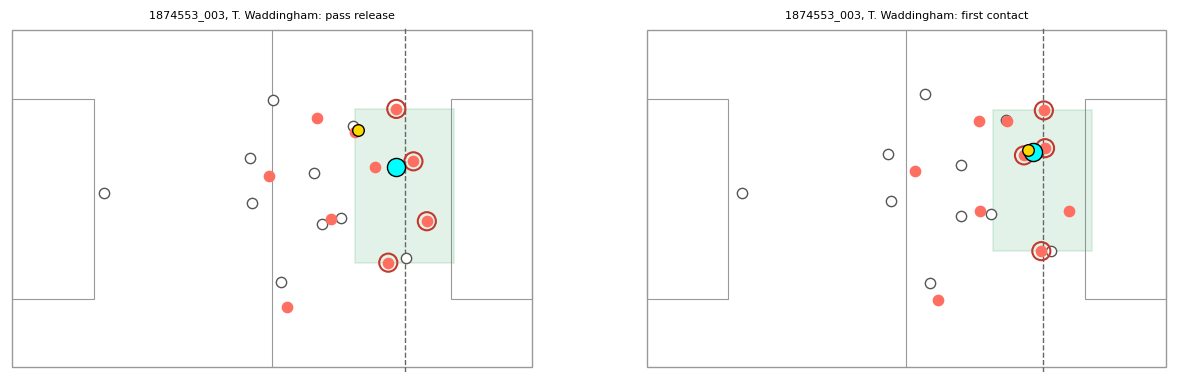

In [3]:
events_match = detection.detect_events(match)
cands_checked = detection.detect_candidates(match)
example = events_match.iloc[2]
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for ax, (name, frame) in zip(axes, (('pass release', example.release_frame), ('first contact', example.contact_frame))):
    draw_event_frame(ax, match, example, frame, f'{example.event_id}, {example.player}: {name}')
plt.show()

Cyan = the striker, gold = the ball, white = his team-mates, red = opponents. Red rings are the back-line members; the green rectangle is the box and the dashed line the line height.

### 2.4 The four gates

A candidate becomes an **event** only if it passes all of these:

| Gate | Rule |
| --- | --- |
| `linked` | pass and first contact are at most 50 frames (5 s) apart; for an intercepted pass the ball must get within 5 m of the forward |
| `from_behind` | the ball travels towards the opposition goal, within 45 degrees of straight (a ball from the side is not a hold-up) |
| `in_box` | the striker is inside the back-line box at release **or** at first contact |
| `not_behind` | at first contact he is at most 1 m past the line (a run in behind is not a hold-up) |

The funnel for this match:

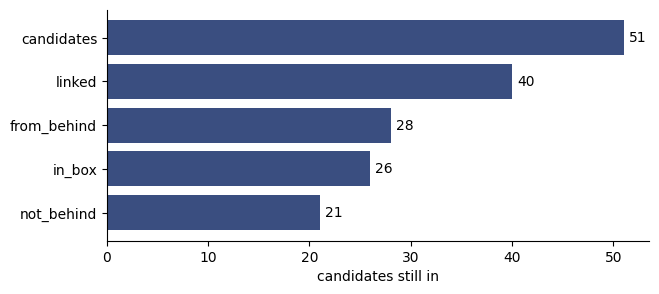

,surviving
candidates,51
linked,40
from_behind,28
in_box,26
not_behind,21


In [4]:
funnel = detection.gate_counts(cands_checked)
fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(funnel.index[::-1], funnel.values[::-1], color=BLUE)
for i, v in enumerate(funnel.values[::-1]): ax.text(v + 0.5, i, str(v), va='center')
ax.set_xlabel('candidates still in'); ax.spines[['top', 'right']].set_visible(False); plt.show()
funnel.to_frame('surviving')

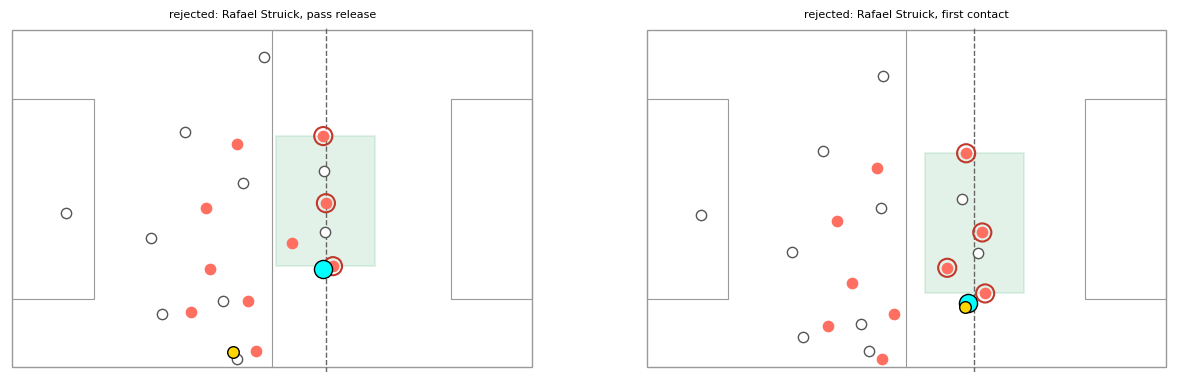

In [5]:
# a candidate the box gate rejected: the striker is not inside the box at either moment
rejected = cands_checked[cands_checked.linked & cands_checked.from_behind & ~cands_checked.in_box]
r = rejected.iloc[0]
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for ax, (name, frame) in zip(axes, (('pass release', r.release_frame), ('first contact', r.contact_frame))):
    draw_event_frame(ax, match, r, frame, f'rejected: {r.player}, {name}')
plt.show()

### 2.5 The event detection dataset

`detect_events` keeps the candidates that pass every gate and gives each an `event_id`. The outcome labels are added next.

## 3. Outcome and value labels (`src/holdup/labels.py`)

**Retained.** The hold-up succeeds if his team still has the ball **3 seconds after his first touch**, whoever has it by then. In order of precedence:

| Result | Rule | Scored as |
| --- | --- | --- |
| `defender_first` | the defender won the ball before he touched it | lost |
| `own_shot` | his possession ends in a shot inside the window | not scored (neither kept nor lost) |
| `foul_won` | his possession ends in a foul suffered, or a free kick / penalty for his team follows | kept |
| `lost` | possession loss, clearance, or an unsuccessful pass inside the window; or an opponent possession starts inside the window; or the ball goes out to the opponent | lost |
| `kept` | none of the above | kept |

His own end type counts only if it falls inside the window: if he is still on the ball after 3 s his team has it, so the hold-up is kept even if he loses it later.

**EPV (value added).** SkillCorner's expected possession value (roughly the chance the possession ends in a goal) from his team's point of view. `epv_before` is the value when he gets the ball; `epv_after` is the value at the start of the next possession (positive if his team has it, negative if the opponent does) when that starts within 50 frames, otherwise the value at the end of his own possession. `value_added = epv_after - epv_before`.

In [6]:
events_all = read_datasets(EVENTS_DIR) if len(list(EVENTS_DIR.glob('*.csv'))) > 1 else None
if events_all is not None:
    print(len(events_all), 'events in', events_all.match_id.nunique(), 'matches;', f'{events_all.retained.mean():.1%} of the scored ones kept')
    display(events_all.result.value_counts().to_frame('events'))
    display(events_all.groupby('result').value_added.agg(['count', 'mean']).round(4))

535 events in 20 matches; 40.5% of the scored ones kept


,events
result,
lost,310
kept,202
own_shot,14
foul_won,9


,count,mean
result,,
foul_won,9,-0.0070
kept,202,-0.0029
lost,297,-0.0429
own_shot,14,0.0526


## 4. Features (`src/holdup/features.py`)

All positions are flipped to attack +x; distances are in metres, speeds in m/s. Each feature is measured at one of two moments: **pass release** (prefix `rel_`, `suprel_`, `_rel`) or **first contact** (prefix `con_`, `sup_`, `_con`). The model is trained on the contact state; the release state gives the odds the striker *inherited* before his own movement and the ball's arrival changed anything.

| Feature | Group | What it measures |
| --- | --- | --- |
| `aerial` | pass | 1 if the pass is flagged a high pass or the ball peaks above 2 m |
| `peak_height` | pass | highest height of the ball between release and contact (m) |
| `flight_s` | pass | time the ball is in the air (s) |
| `pass_distance` | pass | distance from where the ball was played to where the striker is at first contact (m) |
| `origin_x` | pass | x of the ball at release: how deep the pass starts |
| `xpass_raw` / `xpass` | pass | physics chance the pass gets through the defence; `xpass` is the calibrated probability |
| `con_n5`, `rel_n5` | pressure | opposition outfield players within 5 m of the striker |
| `con_oval_sum`, `rel_oval_sum` | pressure | the pressure oval (below) |
| `sup_n_xp60`, `suprel_n_xp60` | support | team-mates he could lay the ball off to with at least a 60% completion chance |
| `sup_n_lane_open`, `suprel_n_lane_open` | support | team-mates with a clear passing lane |
| `pre_speed_con`, `pre_speed_rel` | own movement | his speed over the last 0.5 s |
| `past_line_contact`, `line_dist_release` | own movement | his x minus the back-line height at contact / release (negative = in front of the line) |
| `pre_line_height` | context | how high the back line is, measured from the goal line it defends |

### 4.1 Pass features
Read straight from the ball's tracking between the release and contact frames. The ball's height (`z`) separates ground passes from lofted balls; `aerial` also uses SkillCorner's own `high_pass` flag.

In [7]:
ft = features.pass_features(match, events_match)
pd.concat([events_match[['event_id', 'player', 'outcome']], ft], axis=1).head(8)

,event_id,player,outcome,aerial,peak_height,flight_s,pass_distance,origin_x
0,1874553_001,L. Jovanovic,received,0.0,0.30,0.9,16.691195,-6.19
1,1874553_002,L. Jovanovic,received,0.0,0.24,1.6,23.978399,-12.66
2,1874553_003,T. Waddingham,received,0.0,0.25,0.8,9.299559,17.37
3,1874553_004,T. Waddingham,received,0.0,1.44,0.6,10.256983,-38.68
4,1874553_005,L. Jovanovic,received,1.0,2.84,2.1,23.631322,-27.71
5,1874553_006,T. Waddingham,defender_first,1.0,3.14,1.1,12.169799,14.83
6,1874553_007,L. Jovanovic,received,0.0,0.19,1.6,23.813855,8.90
7,1874553_008,L. Jovanovic,defender_first,1.0,7.77,2.7,28.997643,-14.51


### 4.2 Expected pass completion (`xpass`)
How hard was the pass itself to get through? It uses the ball's **actual path** from release to first contact and every opponent as he is *at the moment of release* (position and velocity).

1. A defender can **intercept at a point of the path** if the ball is low enough there (at most 2 m; a lofted ball cannot be played with the foot while overhead) and he can reach it before the ball does. His time is *reaction (0.5 s) + distance / 7 m/s*, measured from where he would be after reacting; the ball's time is when it arrives at that point.
2. The chance he wins that race is a **logistic of the margin** (spread 0.4 s).
3. The last point of the path (where the ball is first contested) always counts.
4. The pass completes if **no defender gets there**: `P = product over defenders of (1 - best chance over the path)`.
5. That physical number is not yet a probability, so the model-training notebook **calibrates** it (Platt scaling, out of fold by match) against whether the pass was received or intercepted. The features dataset stores the raw value `xpass_raw`; the calibrated `xpass` appears in the model results.

In [8]:
xp = features.xpass_features(match, events_match)
pd.concat([events_match[['event_id', 'player', 'outcome']], xp], axis=1).head(8)

,event_id,player,outcome,xpass_raw
0,1874553_001,L. Jovanovic,received,0.664615
1,1874553_002,L. Jovanovic,received,0.126124
2,1874553_003,T. Waddingham,received,0.478873
3,1874553_004,T. Waddingham,received,0.565876
4,1874553_005,L. Jovanovic,received,0.000120
5,1874553_006,T. Waddingham,defender_first,0.570495
6,1874553_007,L. Jovanovic,received,0.007977
7,1874553_008,L. Jovanovic,defender_first,0.036601


### 4.3 Pressure
Defenders are the opposition's outfield players (goalkeeper excluded).

* `n5`: how many are within 5 m of the striker.
* `oval_sum` (after Andrienko 2017 / Herold 2022): each defender inside an **oval** around the striker adds `(1 - d) ** 1.75`, where `d` is his distance scaled by the oval's reach (0 = on him, 1 = at the edge). The oval reaches **9 m towards goal, 3 m behind and 6 m sideways**, because a defender goal-side of the striker is the one who can win the ball. Pressure is measured at release (`rel_`) and at first contact (`con_`).

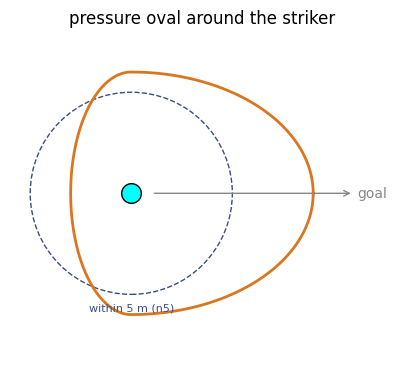

,event_id,player,rel_n5,rel_oval_sum,con_n5,con_oval_sum
0,1874553_001,L. Jovanovic,0.0,0.129563,1.0,0.265003
1,1874553_002,L. Jovanovic,0.0,0.029905,1.0,0.452943
2,1874553_003,T. Waddingham,2.0,0.354385,2.0,0.722996
3,1874553_004,T. Waddingham,1.0,0.576891,1.0,0.601480
4,1874553_005,L. Jovanovic,1.0,0.178362,1.0,0.256316
5,1874553_006,T. Waddingham,2.0,0.449705,1.0,0.272929
6,1874553_007,L. Jovanovic,1.0,0.164228,1.0,0.412849
7,1874553_008,L. Jovanovic,1.0,0.638205,1.0,0.600389


In [9]:
fig, ax = plt.subplots(figsize=(5.5, 4.2))
t = np.linspace(0, 2 * np.pi, 200)
reach = np.where(np.cos(t) >= 0, 9.0, 3.0)
ax.plot(np.cos(t) * reach, np.sin(t) * 6.0, c=ORANGE, lw=2)
ax.scatter([0], [0], c='cyan', s=200, edgecolor='k', zorder=3)
ax.annotate('', xy=(11, 0), xytext=(1, 0), arrowprops=dict(arrowstyle='->', color=GREY)); ax.text(11.2, 0, 'goal', va='center', color=GREY)
ax.add_patch(plt.Circle((0, 0), 5, fill=False, ec=BLUE, ls='--')); ax.text(0, -5.8, 'within 5 m (n5)', ha='center', color=BLUE, fontsize=8)
ax.set_aspect('equal'); ax.set_xlim(-6, 13); ax.set_ylim(-8, 8); ax.set_title('pressure oval around the striker'); ax.axis('off'); plt.show()
pr = features.pressure_features(match, events_match)
pd.concat([events_match[['event_id', 'player']], pr], axis=1).head(8)

### 4.4 Support
Who can the striker lay the ball off to at first contact (and at release)? For every team-mate within 30 m (own goalkeeper excluded):

* **Lane open** (`n_lane_open`): no opponent within 2 m of the straight line from the striker to the team-mate, and the team-mate's nearest opponent is more than 3 m away.
* **Pass completion** (`n_xp60`): the same interception model as for the pass into the hold-up, applied to a straight 14 m/s lay-off. A team-mate is a real option if the pass would complete with probability at least **60%**; `n_xp60` counts them. Opponents include the goalkeeper and move with their measured velocity.

In [10]:
sp = features.support_features(match, events_match, 'contact_frame', 'sup_')
pd.concat([events_match[['event_id', 'player']], sp], axis=1).head(8)

,event_id,player,sup_n_xp60,sup_n_lane_open
0,1874553_001,L. Jovanovic,3.0,4.0
1,1874553_002,L. Jovanovic,3.0,3.0
2,1874553_003,T. Waddingham,1.0,0.0
3,1874553_004,T. Waddingham,1.0,0.0
4,1874553_005,L. Jovanovic,2.0,4.0
5,1874553_006,T. Waddingham,2.0,3.0
6,1874553_007,L. Jovanovic,2.0,3.0
7,1874553_008,L. Jovanovic,2.0,3.0


### 4.5 The striker's own movement and the line
* `pre_speed_rel`, `pre_speed_con`: his speed over the 0.5 s up to release and up to first contact. A striker who is moving when the ball arrives is harder to press but also has less control.
* `past_line_contact` / `line_dist_release`: his x minus the line height. Already measured by the detector.
* `pre_line_height`: half the pitch length minus the line height, i.e. how far the line is from the goal it protects (a high line is a large number).

In [11]:
pre = features.prereceipt_features(match, events_match)
pd.concat([events_match[['event_id', 'player']], pre, events_match[['past_line_contact', 'line_dist_release']]], axis=1).head(8)

,event_id,player,pre_speed_rel,pre_speed_con,pre_line_height,past_line_contact,line_dist_release
0,1874553_001,L. Jovanovic,2.292684,1.653239,34.445,-7.885,-6.365
1,1874553_002,L. Jovanovic,3.092507,3.814184,38.050,-8.950,-6.850
2,1874553_003,T. Waddingham,4.400000,3.918469,25.730,-1.905,-1.870
3,1874553_004,T. Waddingham,0.907083,0.816088,74.165,-8.355,-8.305
4,1874553_005,L. Jovanovic,2.906613,0.611882,56.280,-1.850,-2.550
5,1874553_006,T. Waddingham,4.591645,6.699284,33.330,-0.810,-1.730
6,1874553_007,L. Jovanovic,0.082462,1.634136,21.460,-2.205,-1.310
7,1874553_008,L. Jovanovic,0.592284,5.659717,52.485,-2.375,0.965


## 5. Running the pipeline for one match

`run_event_pipeline(match_id, use_model=False)` does everything above and writes the event and feature datasets. With `use_model=True` it also loads the saved model (trained in notebook 2) and writes the model results. All datasets share `event_id`.

In [12]:
out = run_event_pipeline(MATCH_ID, use_model=False, save=False, match=match)
print({k: v.shape for k, v in out.items()})
out['events'].head(3)

{'events': (21, 50), 'features': (21, 20)}


,event_id,match_id,source_event_id,player_id,player,team_id,position,release_frame,contact_frame,gap,passer_id,origin,outcome,striker_x_release,striker_y_release,striker_x_contact,striker_y_contact,line_x_release,line_x_contact,line_dist_release,...,ball_x_contact,ball_y_contact,arrival_distance,linked,from_behind,in_box,not_behind,in_box_release,in_box_contact,team_name,result,reason,hold_seconds,frames_to_loss,retained,end_type,epv_before,epv_after,after_source,value_added
0,1874553_001,1874553,8_134,797295,L. Jovanovic,866,CF,7087.0,7096,9.0,809759.0,open_play,received,11.69,1.37,10.47,0.16,18.055,18.355,-6.365,...,9.29,0.04,NaN,True,True,True,True,True,True,Adelaide United,lost,possession_loss,0.9,9.0,0.0,possession_loss,0.0540,-0.0293,next possession,-0.0833
1,1874553_002,1874553,8_170,797295,L. Jovanovic,866,CF,10620.0,10636,16.0,26766.0,open_play,received,7.60,-1.68,10.54,-6.39,14.450,19.490,-6.850,...,9.97,-6.45,NaN,True,True,True,True,True,True,Adelaide United,lost,pass_unsuccessful,2.7,27.0,0.0,pass,0.0624,-0.0198,next possession,-0.0822
2,1874553_003,1874553,8_240,795537,T. Waddingham,1802,CF,14107.0,14115,8.0,51002.0,open_play,received,24.90,6.36,25.60,9.51,26.770,27.505,-1.870,...,24.47,9.85,NaN,True,True,True,True,True,True,Brisbane FC,kept,no opponent possession in window,1.1,NaN,1.0,pass,0.0501,0.0363,next possession,-0.0138


In [13]:
out['features'].head(3)

,event_id,aerial,peak_height,flight_s,pass_distance,origin_x,xpass_raw,rel_n5,rel_oval_sum,con_n5,con_oval_sum,sup_n_xp60,sup_n_lane_open,suprel_n_xp60,suprel_n_lane_open,pre_speed_rel,pre_speed_con,pre_line_height,past_line_contact,line_dist_release
0,1874553_001,0.0,0.30,0.9,16.691195,-6.19,0.664615,0.0,0.129563,1.0,0.265003,3.0,4.0,2.0,4.0,2.292684,1.653239,34.445,-7.885,-6.365
1,1874553_002,0.0,0.24,1.6,23.978399,-12.66,0.126124,0.0,0.029905,1.0,0.452943,3.0,3.0,3.0,4.0,3.092507,3.814184,38.050,-8.950,-6.850
2,1874553_003,0.0,0.25,0.8,9.299559,17.37,0.478873,2.0,0.354385,2.0,0.722996,1.0,0.0,1.0,1.0,4.400000,3.918469,25.730,-1.905,-1.870


In [14]:
if MODEL_PATH.exists():
    out_model = run_event_pipeline(MATCH_ID, use_model=True, save=False, match=match)
    display(out_model['results'].round(3).head(5))
    merged = out_model['events'][['event_id', 'player', 'outcome', 'retained']].merge(out_model['features'][['event_id', 'xpass_raw', 'con_oval_sum']], on='event_id').merge(out_model['results'][['event_id', 'xpass', 'xr_release', 'xr_contact', 'roe']], on='event_id')
    display(merged.round(3).head(5))
else:
    print('No saved model yet: run notebook 2 first, then re-run this cell.')

,event_id,xpass,xr_release,xr_contact,setup,setup_c,duel,roe,roe_c,exp_value,voe
0,1874553_001,0.832,0.689,0.775,0.086,0.092,-0.775,-0.689,-0.683,-0.013,-0.070
1,1874553_002,0.684,0.745,0.722,-0.024,-0.018,-0.722,-0.745,-0.740,-0.015,-0.067
2,1874553_003,0.795,0.349,0.399,0.050,0.056,0.601,0.651,0.657,-0.028,0.015
3,1874553_004,0.813,0.344,0.348,0.003,0.009,-0.348,-0.344,-0.338,-0.021,0.025
4,1874553_005,0.311,0.181,0.341,0.160,0.166,0.659,0.819,0.825,-0.025,0.023


,event_id,player,outcome,retained,xpass_raw,con_oval_sum,xpass,xr_release,xr_contact,roe
0,1874553_001,L. Jovanovic,received,0.0,0.665,0.265,0.832,0.689,0.775,-0.689
1,1874553_002,L. Jovanovic,received,0.0,0.126,0.453,0.684,0.745,0.722,-0.745
2,1874553_003,T. Waddingham,received,1.0,0.479,0.723,0.795,0.349,0.399,0.651
3,1874553_004,T. Waddingham,received,0.0,0.566,0.601,0.813,0.344,0.348,-0.344
4,1874553_005,L. Jovanovic,received,1.0,0.000,0.256,0.311,0.181,0.341,0.819


The merged table shows the three datasets joined on `event_id`. Run `run_many()` from `holdup.pipelines` to process every match (about 25 seconds each); notebook 2 trains on those files and notebook 3 turns the model results into player stats.